**Studi Kasus: Klasifikasi Otomatis Pemicu Deforestasi (Driver Attribution) Menggunakan Deep Learning & Citra Satelit**

**Latar Belakang:** Sistem peringatan dini deforestasi berbasis satelit (seperti Sentinel-1 dan Sentinel-2) mampu mendeteksi hilangnya tutupan pohon secara mingguan. Namun, sistem tersebut sering kali hanya memberikan lokasi tanpa mengetahui penyebab langsung (direct driver) dari deforestasi tersebut.

**Tantangan:** Mengklasifikasikan apakah suatu area yang terganggu di hutan disebabkan oleh Pertanian Skala Kecil, Pertanian Skala Besar, Penambangan (Mining), Penebangan Liar (Logging), atau Kebakaran Hutan (Wildfire).

**Solusi Studi Kasus:**
Membangun model Convolutional Neural Network (CNN) dasar di Google Colab untuk melakukan klasifikasi gambar (image classification) pada patch citra satelit area terganggu ke dalam kategori pemicu deforestasi.

Menggunakan TensorFlow versi: 2.21.0
Shape Data Pelatihan: (1000, 64, 64, 3)
Shape Label Pelatihan: (1000, 1)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 62, 62, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 29, 29, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 12, 12, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 9216)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │       589,888 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 646,533 (2.47 MB)

 Trainable params: 646,533 (2.47 MB)

 Non-trainable params: 0 (0.00 B)


Memulai pelatihan model CNN...
Epoch 1/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 8s 188ms/step - accuracy: 0.2000 - loss: 1.6160 - val_accuracy: 0.1750 - val_loss: 1.6184
Epoch 2/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 11s 226ms/step - accuracy: 0.2070 - loss: 1.6087 - val_accuracy: 0.1550 - val_loss: 1.6118
Epoch 3/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 6s 188ms/step - accuracy: 0.2170 - loss: 1.6081 - val_accuracy: 0.1550 - val_loss: 1.6210
Epoch 4/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 10s 181ms/step - accuracy: 0.2150 - loss: 1.6105 - val_accuracy: 0.1550 - val_loss: 1.6173
Epoch 5/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 7s 224ms/step - accuracy: 0.2230 - loss: 1.6084 - val_accuracy: 0.1550 - val_loss: 1.6163
Epoch 6/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 10s 207ms/step - accuracy: 0.2170 - loss: 1.6092 - val_accuracy: 0.1550 - val_loss: 1.6148
Epoch 7/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 9s 178ms/step - accuracy: 0.2240 - loss: 1.6070 - val_accuracy: 0.1550 - val_loss: 1.6152
Epoch 8/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 7s 222ms/step - accuracy: 0.216

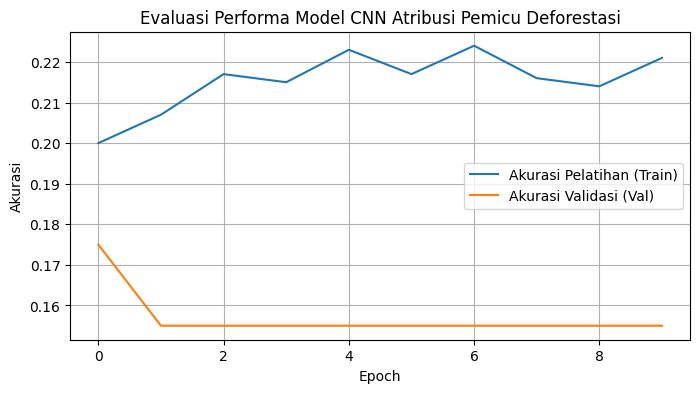

In [ ]:
# ==========================================
# 1. IMPORT LIBRARIES
# ==========================================
import tensorflow as tf
from tensorflow.keras import datasets, layers, models
import matplotlib.pyplot as plt
import numpy as np

print("Menggunakan TensorFlow versi:", tf.__version__)

# ==========================================
# 2. PERSIAPAN DATASET SIMULASI CITRA SATELIT
# ==========================================
# Dalam implementasi nyata, Anda akan memuat patch citra Sentinel-1/2 (ukuran 64x64 piksel, multi-channel).
# Di sini, kita mensimulasikan dataset citra (1000 sampel pelatihan, 200 sampel pengujian) dengan ukuran 64x64 dan 3 channel (RGB/Multi-band).

np.random.seed(42)
X_train = np.random.rand(1000, 64, 64, 3)
# 5 Kelas Pemicu Deforestasi: 0=Pertanian Kecil, 1=Pertanian Besar, 2=Mining, 3=Logging, 4=Wildfire
y_train = np.random.randint(0, 5, size=(1000, 1))

X_test = np.random.rand(200, 64, 64, 3)
y_test = np.random.randint(0, 5, size=(200, 1))

class_names = ['Pertanian Kecil', 'Pertanian Besar', 'Mining (Tambang)', 'Logging (Penebangan)', 'Wildfire (Kebakaran)']

print("Shape Data Pelatihan:", X_train.shape)
print("Shape Label Pelatihan:", y_train.shape)

# ==========================================
# 3. MEMBANGUN ARSITEKTUR MODEL CNN (Deep Learning)
# ==========================================
# Mengikuti prinsip materi Dr. Bart: CNN mengekstrak pola spasial & konteks dari piksel sekitar.

model = models.Sequential([
    # Blok Konvolusi 1
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(64, 64, 3)),
    layers.MaxPooling2D((2, 2)),

    # Blok Konvolusi 2
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Blok Konvolusi 3 (Menangkap konteks spasial yang lebih kompleks)
    layers.Conv2D(64, (3, 3), activation='relu'),

    # Fully Connected Layers (Klasifikasi)
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.5), # Mencegah overfitting
    layers.Dense(5, activation='softmax') # 5 kelas driver deforestasi
])

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

model.summary()

# ==========================================
# 4. PELATIHAN MODEL (Training)
# ==========================================
print("\nMemulai pelatihan model CNN...")
history = model.fit(X_train, y_train, epochs=10,
                    validation_data=(X_test, y_test),
                    batch_size=32)

# ==========================================
# 5. EVALUASI DAN VISUALISASI HASIL
# ==========================================
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=2)
print(f"\nAkurasi Pengujian Model (Test Accuracy): {test_acc * 100:.2f}%")

# Plot Grafik Akurasi Pelatihan
plt.figure(figsize=(8, 4))
plt.plot(history.history['accuracy'], label='Akurasi Pelatihan (Train)')
plt.plot(history.history['val_accuracy'], label='Akurasi Validasi (Val)')
plt.title('Evaluasi Performa Model CNN Atribusi Pemicu Deforestasi')
plt.xlabel('Epoch')
plt.ylabel('Akurasi')
plt.legend()
plt.grid(True)
plt.show()